# TTK4115 — Helicopter Lab 3: post-processing

**Part III: Luenberger observer** · Experimental data from the laboratory

This notebook processes the provided MATLAB recordings for:

- **Task 1 — IMU characteristics:** raw gyroscope versus encoder rates, and accelerometer signals.
- **Task 2 — Transformations:** IMU-derived angles and transformed gyroscope rates versus the encoders.
- **Observer experimentation:** recorded Luenberger observer states versus encoder measurements for all six recorded configurations.

All plots are exported to `../Plots/` as both **PNG** (report/preview) and **PDF** (vector graphics for LaTeX). The raw files are preserved under `Input/`.

> **Important data-quality finding:** Every channel of every `task34_y*.mat` file is exactly zero, even though the corresponding encoder files show motion. Several observer estimates are also identically zero. The observer plots therefore illustrate the *recorded behavior*, **not a validated measurement-based observer**. See the checks and the `README.md` for further details.

**Recording note supplied with the files:** `Newintegral=0.2`. The log filenames do not establish which runs used this setting, so no run-specific claim is made.


## 1. Setup and data format

MATLAB `To File` recordings use the `ans` variable. The first row is **time [s]**; subsequent rows are signals. Sampling is at **0.002 s (500 Hz)**. Only NumPy, SciPy and Matplotlib are needed for plotting.

Run this notebook from its `Notebook` folder; the short path fallback also supports launching from the enclosing project folder.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

BASE = Path.cwd()
if not (BASE / "Input").is_dir():
    BASE = BASE / "Notebook"
INPUT = BASE / "Input"
PLOTS = BASE.parent / "Plots"
PLOTS.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "font.size": 10,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})


def load_recording(filename):
    data = loadmat(INPUT / filename)["ans"]
    return data[0], data[1:]  # time, signals


def save_plot(fig, filename):
    fig.savefig(PLOTS / f"{filename}.png", bbox_inches="tight")
    fig.savefig(PLOTS / f"{filename}.pdf", bbox_inches="tight")
    plt.show()

print(f"Input files: {len(list(INPUT.glob('*.mat')))} MAT files")
print(f"Plot directory: {PLOTS.resolve()}")

Input files: 24 MAT files
Plot directory: /mnt/data/Lab_3_Postprocessing/Plots


### Signal order (verified against `heli_q8lab3.slx`)

The **encoder** recordings contain six channels in the following order:

| Signal row after time | 1 | 2 | 3 | 4 | 5 | 6 |
|:--|:--|:--|:--|:--|:--|:--|
| Encoder | Travel $\lambda$ | Travel rate $\dot\lambda$ | Pitch $p$ | Pitch rate $\dot p$ | Elevation $e$ | Elevation rate $\dot e$ |

Both the transformed Task 2 recording and the observer **measurement/estimate** vectors have five channels in the order

$$[p,\; \dot p,\; e,\; \dot e,\; \dot\lambda]^\mathsf{T}.$$

The raw gyroscope contains **pitch, elevation and travel rotational-rate channels**, but these initially refer to the sensor/body orientation; they will not necessarily agree with the encoder-derived Euler rates during combined rotations.


In [2]:
# Indices refer to signal arrays AFTER the time row has been removed.
ENCODER_STATE_ROWS = [2, 3, 4, 5, 1]
STATE_NAMES = ["Pitch", "Pitch rate", "Elevation", "Elevation rate", "Travel rate"]
STATE_UNITS = ["rad", "rad/s", "rad", "rad/s", "rad/s"]

# Quick sanity check for all recordings (not just selected plots).
for path in sorted(INPUT.glob("*.mat")):
    t, signals = load_recording(path.name)
    if not (np.all(np.isfinite(signals)) and np.all(np.isfinite(t))):
        print(f"WARNING: nonfinite samples in {path.name}")
    if not np.all(np.diff(t) > 0):
        print(f"WARNING: non-increasing timestamps in {path.name}")
print("All recording timestamps are increasing and all numeric values are finite.")

All recording timestamps are increasing and all numeric values are finite.


## 2. Task 1 — IMU characteristics

The rotors are off and the helicopter is moved manually. Compare the three gyroscope channels against encoder rates. The gyroscope axes are presented in the pitch/elevation/travel order used in the supplied model. Agreement is expected to deteriorate when the helicopter is rotated about multiple axes because sensor-body rates differ from Euler rates.

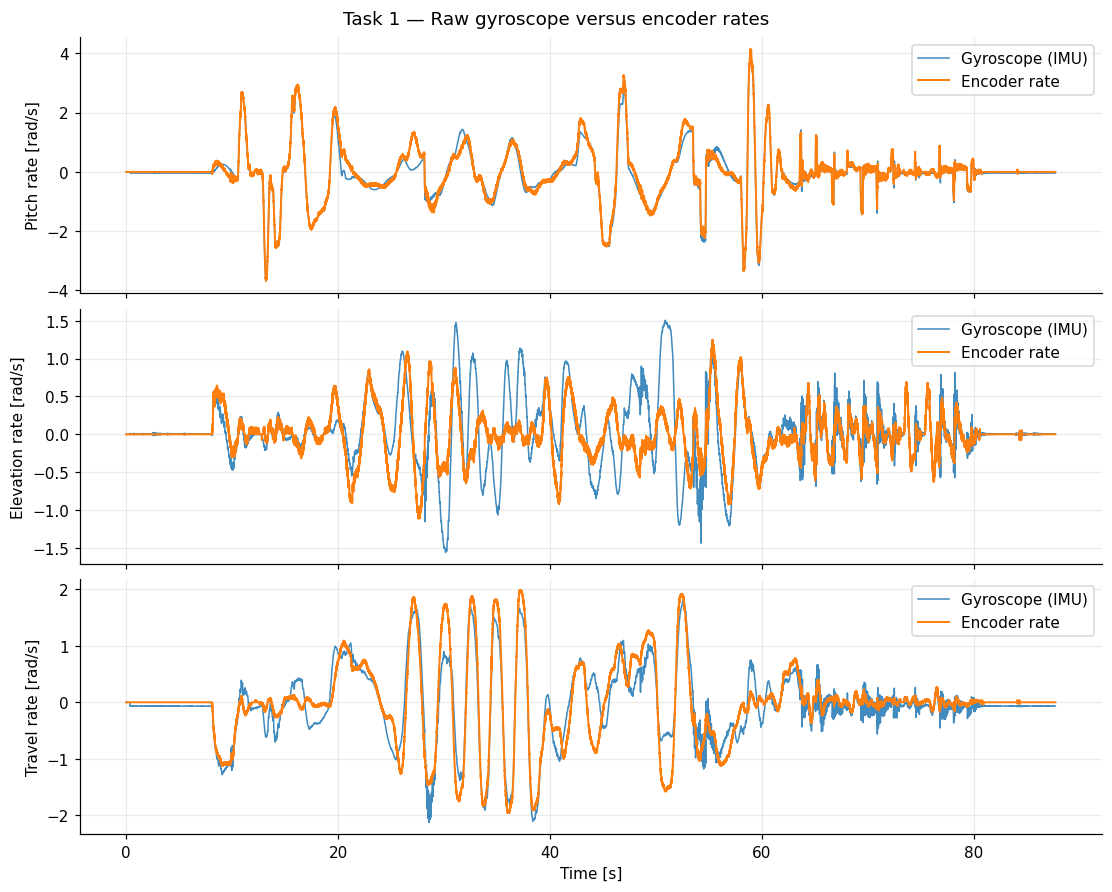

In [3]:
t31, enc31 = load_recording("task31_enkoder.mat")
_, gyro31 = load_recording("task31_gyro.mat")
_, acc31 = load_recording("task31_acc.mat")

fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True, layout="constrained")
for i, (row, name) in enumerate(zip([3, 5, 1], ["Pitch", "Elevation", "Travel"])):
    axs[i].plot(t31, gyro31[i], label="Gyroscope (IMU)", lw=1.0, alpha=0.85)
    axs[i].plot(t31, enc31[row], label="Encoder rate", lw=1.3)
    axs[i].set_ylabel(f"{name} rate [rad/s]")
    axs[i].legend(loc="upper right")
axs[-1].set_xlabel("Time [s]")
fig.suptitle("Task 1 — Raw gyroscope versus encoder rates")
save_plot(fig, "3.1_gyro_vs_encoder")

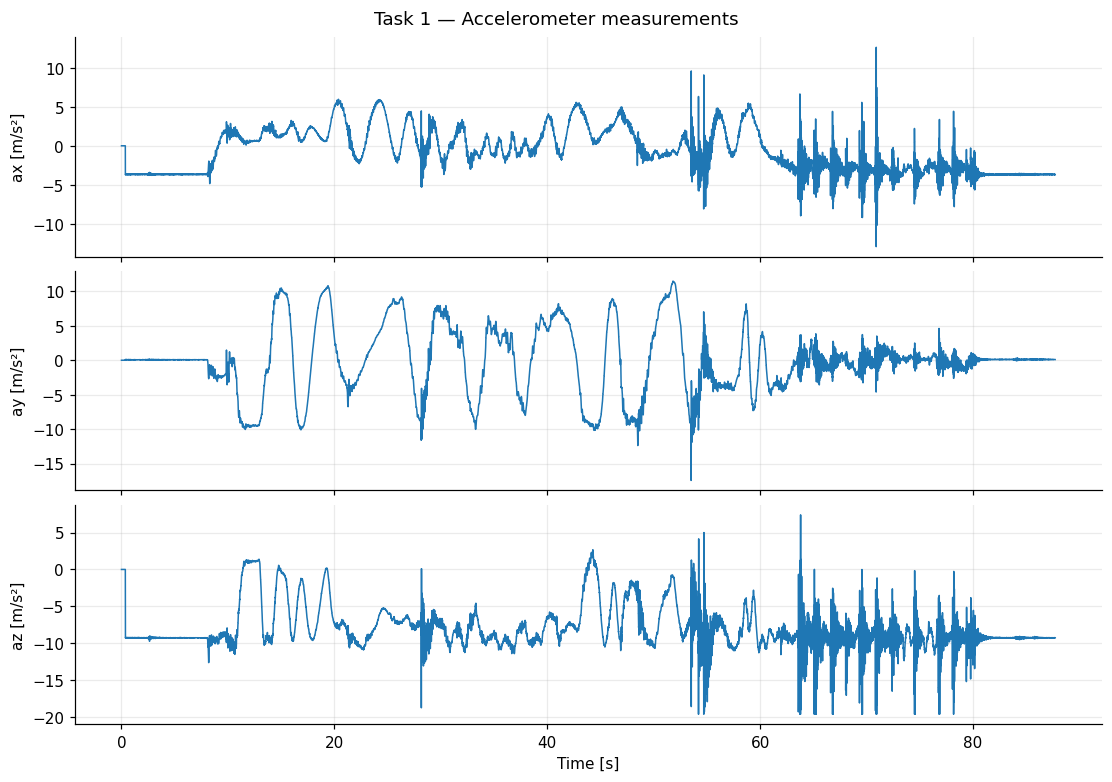

Median accelerometer magnitude (after t = 2 s): 9.96 m/s² (gravity ≈ 9.81 m/s²).


In [4]:
fig, axs = plt.subplots(3, 1, figsize=(10, 7), sharex=True, layout="constrained")
for i, axis in enumerate(["x", "y", "z"]):
    axs[i].plot(t31, acc31[i], lw=1)
    axs[i].set_ylabel(f"a{axis} [m/s²]")
axs[-1].set_xlabel("Time [s]")
fig.suptitle("Task 1 — Accelerometer measurements")
save_plot(fig, "3.1_accelerometer")

magnitude = np.linalg.norm(acc31, axis=0)
print(f"Median accelerometer magnitude (after t = 2 s): "
      f"{np.median(magnitude[t31 > 2]):.2f} m/s² (gravity ≈ 9.81 m/s²).")

## 3. Task 2 — IMU transformations

The accelerometer-derived **pitch and elevation** angles should be compared with their encoder equivalents. The transformed angular rates should be compared with the encoders, using the raw gyroscope as a reference. Large movements can invalidate the assumption that the accelerometer measures gravity alone.

**Caution:** The pitch-angle calculation uses an arctangent with an effective ±π/2 principal-value range; expect disagreements when the real pitch leaves that range. Elevation has an appreciable offset in this recording.

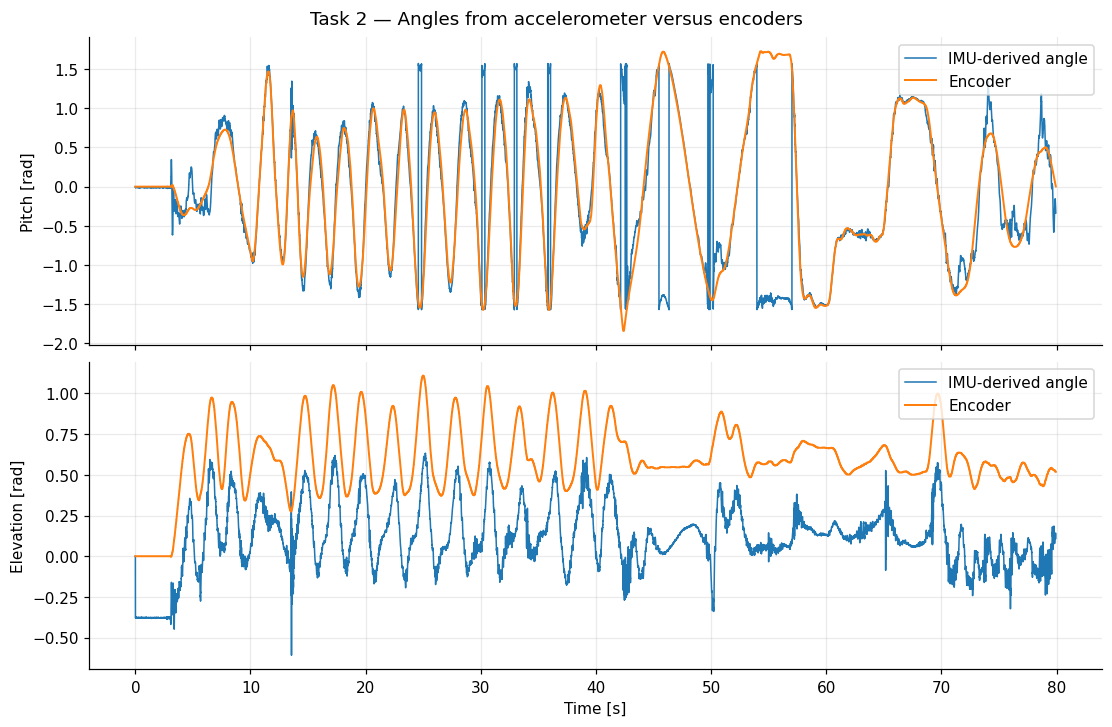

In [5]:
t32, enc32 = load_recording("task32_enkoder.mat")
_, gyro32 = load_recording("task32_gyro.mat")
_, transformed32 = load_recording("task32_euleranglestransformed.mat")

fig, axs = plt.subplots(2, 1, figsize=(10, 6.5), sharex=True, layout="constrained")
for ax, state_i, encoder_i, label in zip(axs, [0, 2], [2, 4], ["Pitch", "Elevation"]):
    ax.plot(t32, transformed32[state_i], lw=1, label="IMU-derived angle")
    ax.plot(t32, enc32[encoder_i], lw=1.3, label="Encoder")
    ax.set_ylabel(f"{label} [rad]")
    ax.legend(loc="upper right")
axs[-1].set_xlabel("Time [s]")
fig.suptitle("Task 2 — Angles from accelerometer versus encoders")
save_plot(fig, "3.2_acc_angles_vs_encoder")

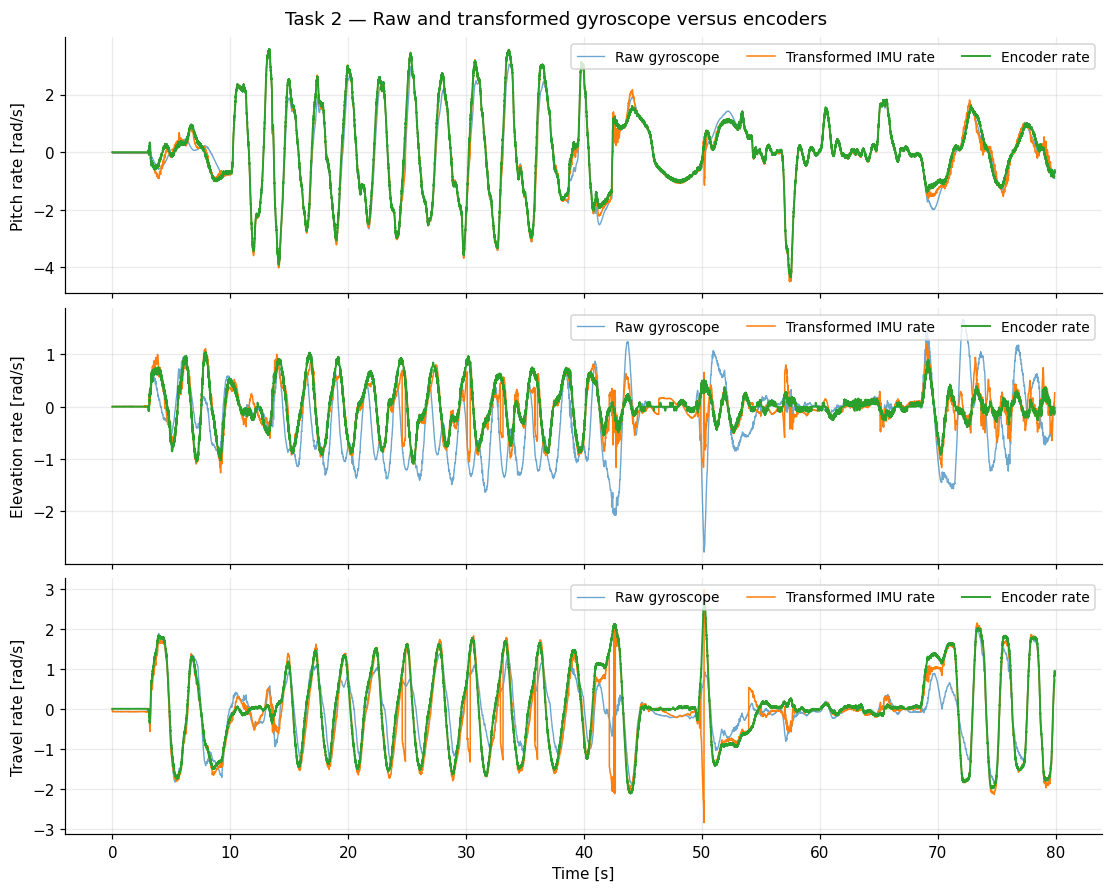

In [6]:
fig, axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True, layout="constrained")
for i, (state_i, encoder_i, name) in enumerate(zip([1, 3, 4], [3, 5, 1], ["Pitch", "Elevation", "Travel"])):
    axs[i].plot(t32, gyro32[i], lw=0.9, alpha=0.65, label="Raw gyroscope")
    axs[i].plot(t32, transformed32[state_i], lw=1.0, label="Transformed IMU rate")
    axs[i].plot(t32, enc32[encoder_i], lw=1.25, label="Encoder rate")
    axs[i].set_ylabel(f"{name} rate [rad/s]")
    axs[i].legend(loc="upper right", ncol=3, fontsize=9)
axs[-1].set_xlabel("Time [s]")
fig.suptitle("Task 2 — Raw and transformed gyroscope versus encoders")
save_plot(fig, "3.2_transformed_rates_vs_encoder")

In [7]:
# Numerical comparison (descriptive statistics, not a full sensor calibration).
print("Task 2: transformed IMU versus encoder")
for i, row in enumerate(ENCODER_STATE_ROWS):
    a = transformed32[i, t32 > 5]
    b = enc32[row, t32 > 5]
    corr = np.corrcoef(a, b)[0, 1]
    rmse = np.sqrt(np.mean((a - b)**2))
    bias = np.mean(a - b)
    print(f"  {STATE_NAMES[i]:14s}  correlation={corr:+.3f}  "
          f"RMSE={rmse:.3f} {STATE_UNITS[i]}  mean difference={bias:+.3f}")
print("Different reference frames, dynamics and offsets can all contribute to differences.")

Task 2: transformed IMU versus encoder
  Pitch           correlation=+0.533  RMSE=0.867 rad  mean difference=-0.078
  Pitch rate      correlation=+0.992  RMSE=0.188 rad/s  mean difference=-0.061
  Elevation       correlation=+0.852  RMSE=0.495 rad  mean difference=-0.486
  Elevation rate  correlation=+0.826  RMSE=0.247 rad/s  mean difference=-0.054
  Travel rate     correlation=+0.878  RMSE=0.493 rad/s  mean difference=-0.137
Different reference frames, dynamics and offsets can all contribute to differences.


## 4. Observer experiments — recorded data (Task 3 / `task34_*`)

Each `task34_*` recording group contains:

- `enkoder`: encoder ground reference (six channels)
- `y`: five observer measurement inputs, expected to be $[p,\dot p,e,\dot e,\dot\lambda]^\mathsf{T}$
- `xhat`: five estimated states in the same order

The file suffixes below are **recording identifiers**, presumably describing tuning choices. The supplied MATLAB initialization file only documents one observer pole vector, $[-25,-25,-25,-25,-25]$. Other exact configurations cannot be independently verified from the recorded filenames, so the plots deliberately use the original suffixes rather than attributing unverified parameters.

> All `y` signals are exactly zero. This does not represent plausible physical IMU measurements during helicopter motion; it prevents a meaningful evaluation of estimator accuracy from these logs. Encoder-versus-estimate plots are still supplied so that the actual recorded behavior remains visible.


In [8]:
RUN_IDS = [
    "-25-25-25-25-25",
    "-10-10-10-10-10",
    "-1-1-1-1-1",
    "-25",
    "0",
    "1",
]

# Count samples and detect channels that never change.
print(f"{'Run suffix':<23} {'Duration':>9} {'y all zero':>12} {'xhat zero rows':>18} {'max |e_rate hat|':>18}")
for run in RUN_IDS:
    t, enc = load_recording(f"task34_enkoder{run}.mat")
    ty, y = load_recording(f"task34_y{run}.mat")
    tx, xhat = load_recording(f"task34_xhat{run}.mat")
    assert len(t) == len(ty) == len(tx) and np.array_equal(t, ty) and np.array_equal(t, tx)
    zeros = [i+1 for i, s in enumerate(xhat) if np.all(s == 0)]
    print(f"{run:<23} {t[-1]:>8.2f}s {str(np.all(y == 0)):>12} "
          f"{str(zeros):>18} {np.max(np.abs(xhat[3])):>18.3f}")

Run suffix               Duration   y all zero     xhat zero rows   max |e_rate hat|
-25-25-25-25-25            45.07s         True          [1, 3, 5]              0.132
-10-10-10-10-10            39.83s         True          [1, 3, 5]              0.125
-1-1-1-1-1                 35.28s         True          [1, 3, 5]              0.924
-25                        24.86s         True          [1, 3, 5]              0.070
0                          41.22s         True          [1, 3, 5]              2.218
1                           8.66s         True          [1, 3, 5]             23.764


### Measurement-input diagnostic

An example is shown below for the file suffix `-25-25-25-25-25`: the entire measurement vector `y` is zero while the encoders register motion. The other five recorded runs exhibit the same all-zero `y` issue.

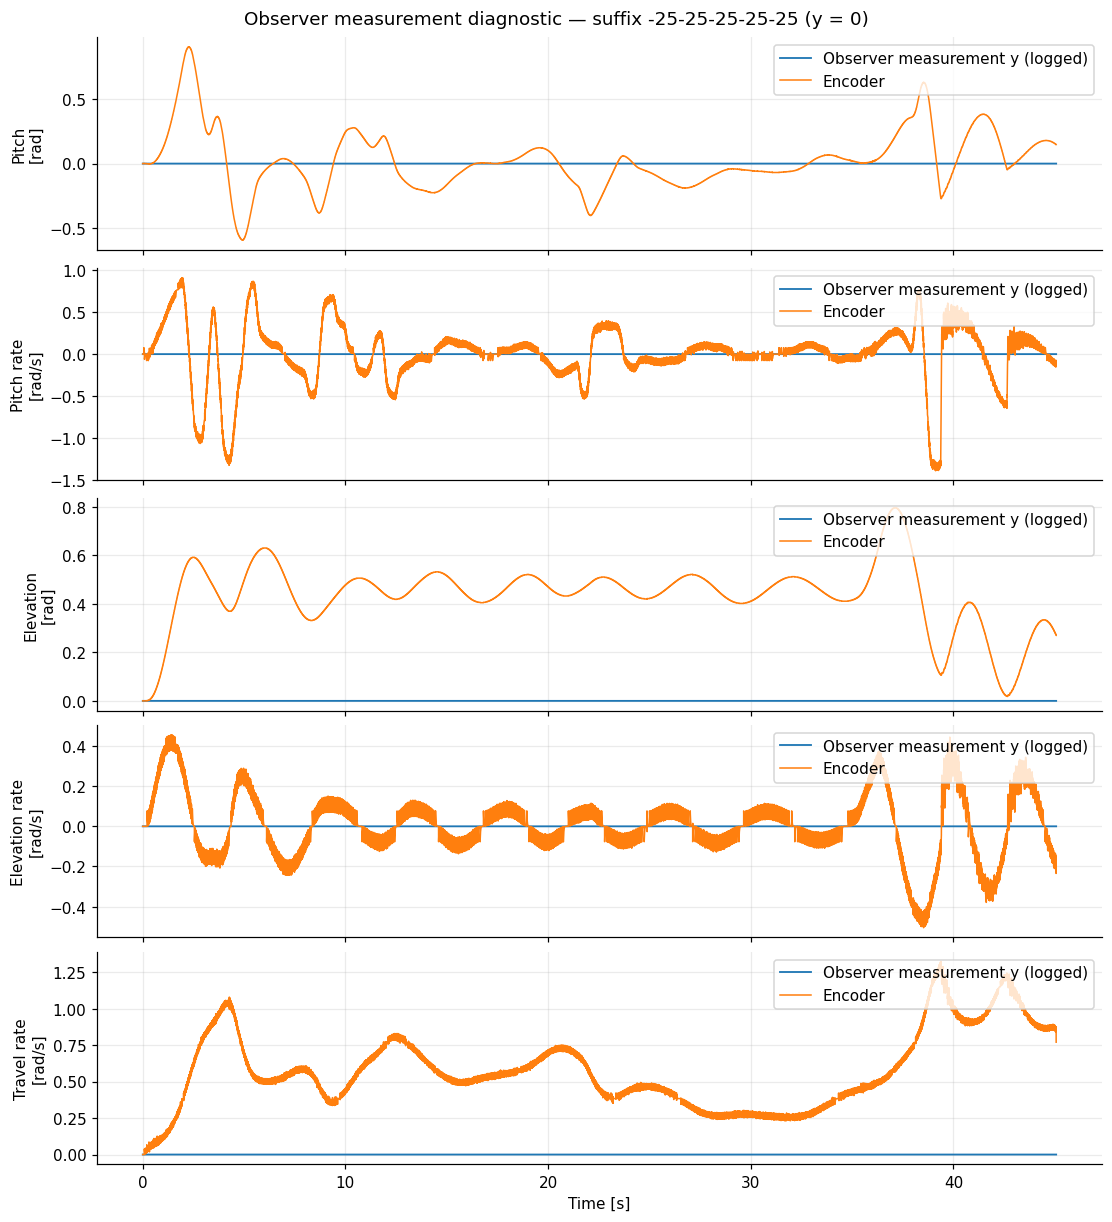

In [9]:
run = "-25-25-25-25-25"
t, enc = load_recording(f"task34_enkoder{run}.mat")
_, y = load_recording(f"task34_y{run}.mat")

fig, axs = plt.subplots(5, 1, figsize=(10, 11), sharex=True, layout="constrained")
for i, ax in enumerate(axs):
    ax.plot(t, y[i], label="Observer measurement y (logged)", lw=1.2)
    ax.plot(t, enc[ENCODER_STATE_ROWS[i]], label="Encoder", lw=1)
    ax.set_ylabel(f"{STATE_NAMES[i]}\n[{STATE_UNITS[i]}]")
    ax.legend(loc="upper right")
axs[-1].set_xlabel("Time [s]")
fig.suptitle(f"Observer measurement diagnostic — suffix {run} (y = 0)")
save_plot(fig, "3.4_00_all_zero_imu_measurements")

### Observer estimate versus encoder, for every recorded run

One figure is generated per configuration. Each figure overlays the five estimated states with the corresponding encoder values. **Do not interpret differences between figures as a fair pole-tuning comparison**: the experiments have different durations, and identical reference inputs/motion are not documented.

Any growth in the estimates (especially for suffix `1`) is shown without clipping or altering the source data.

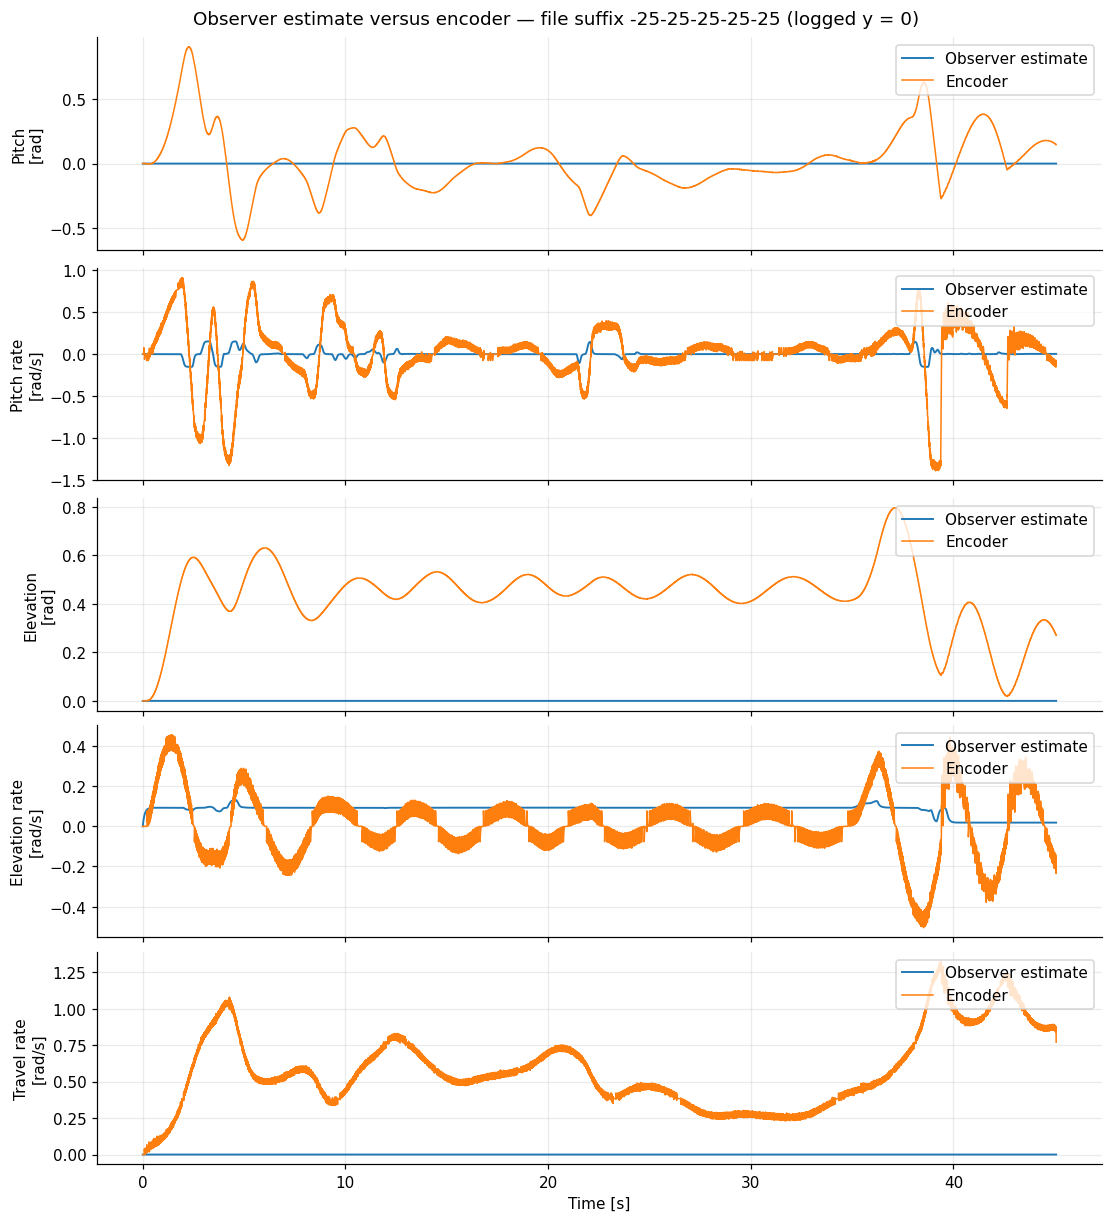

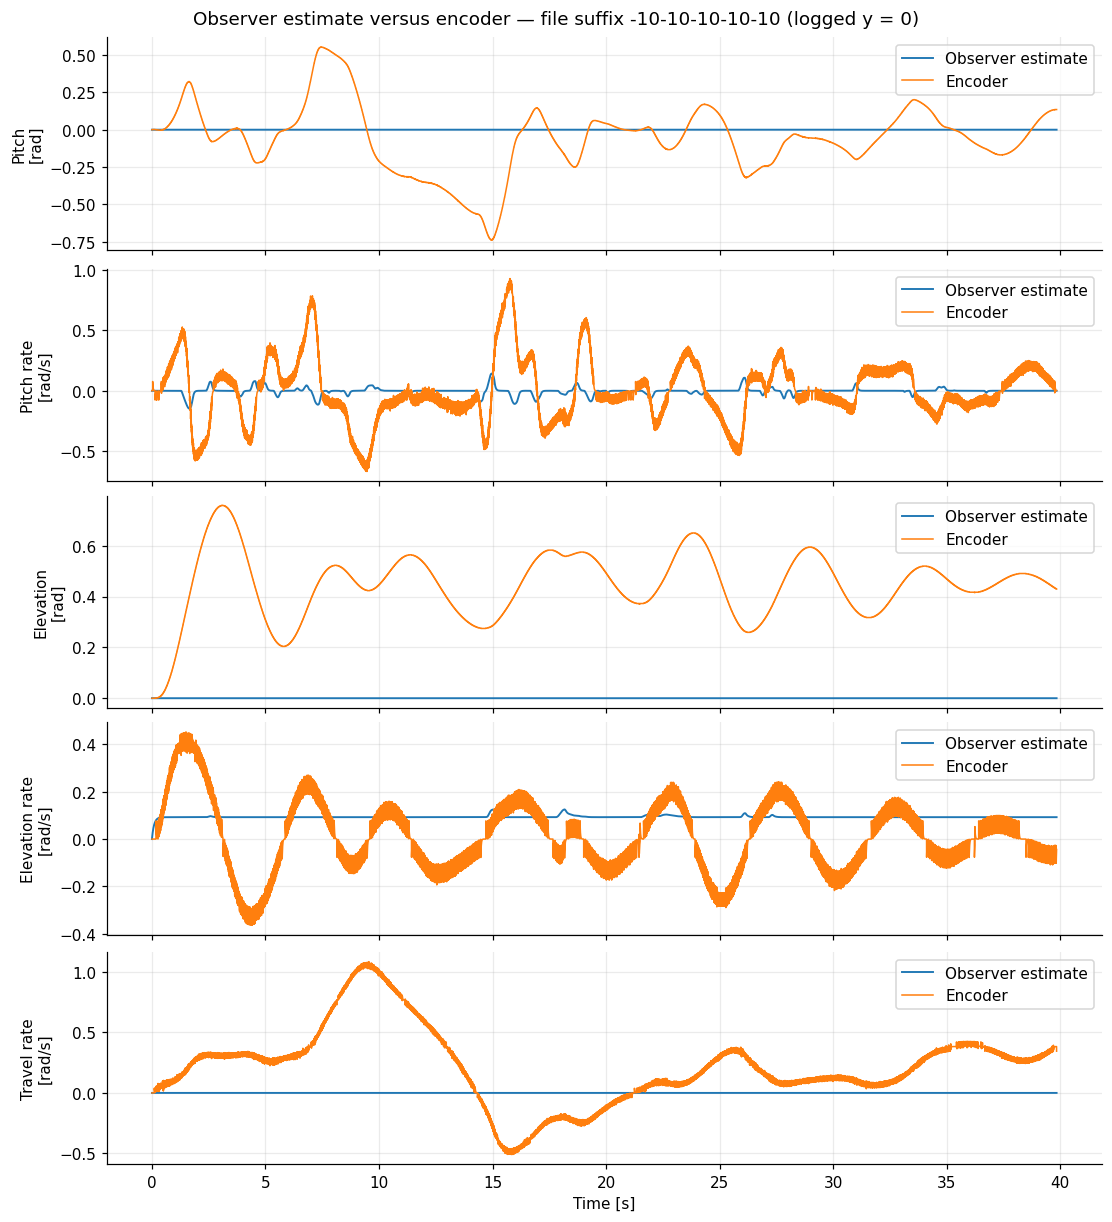

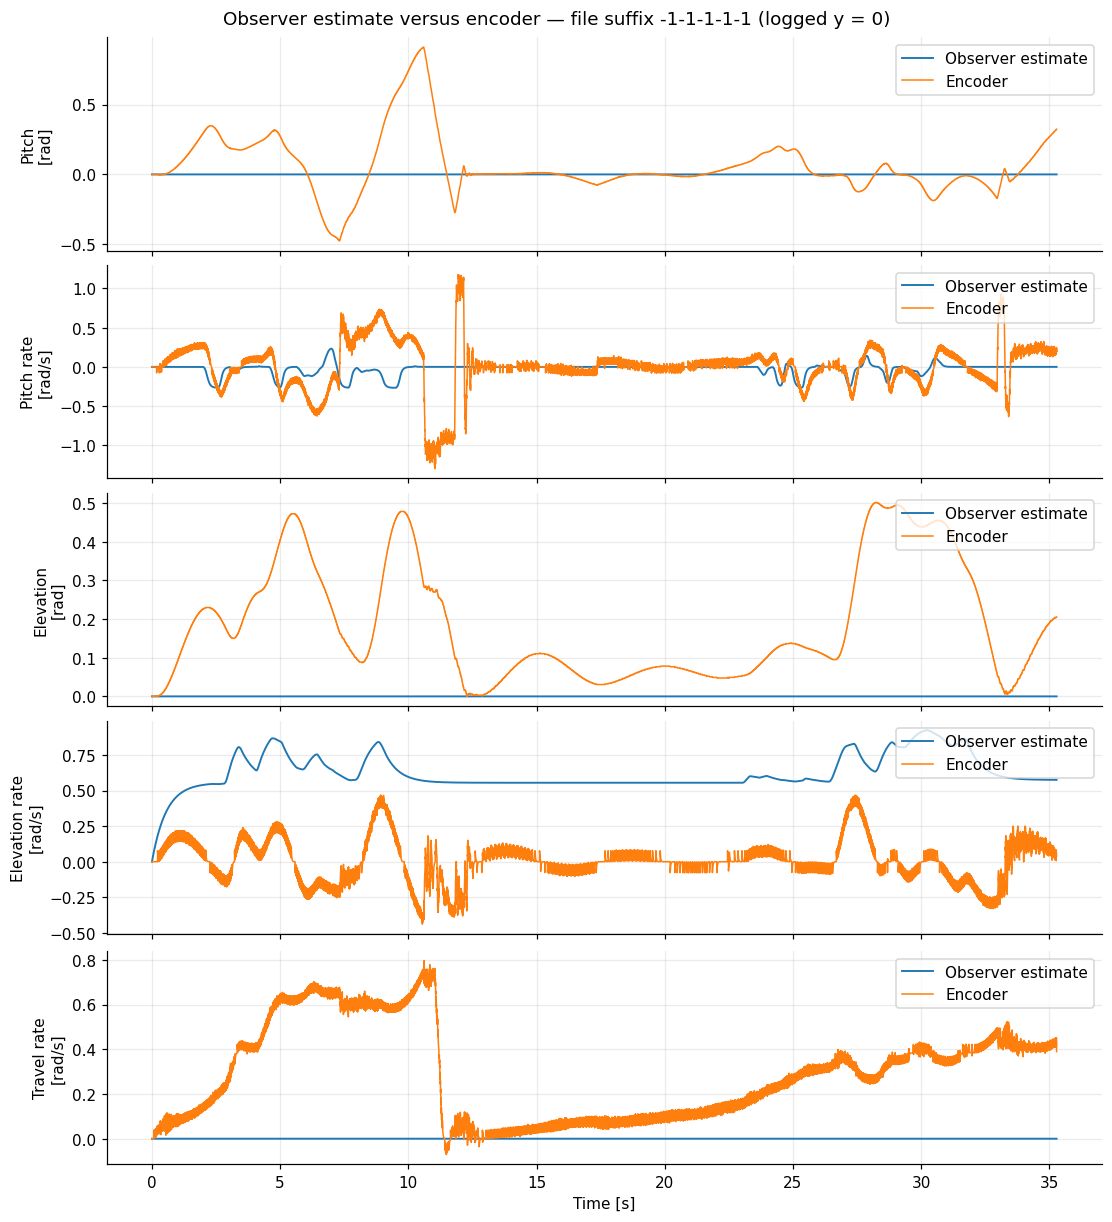

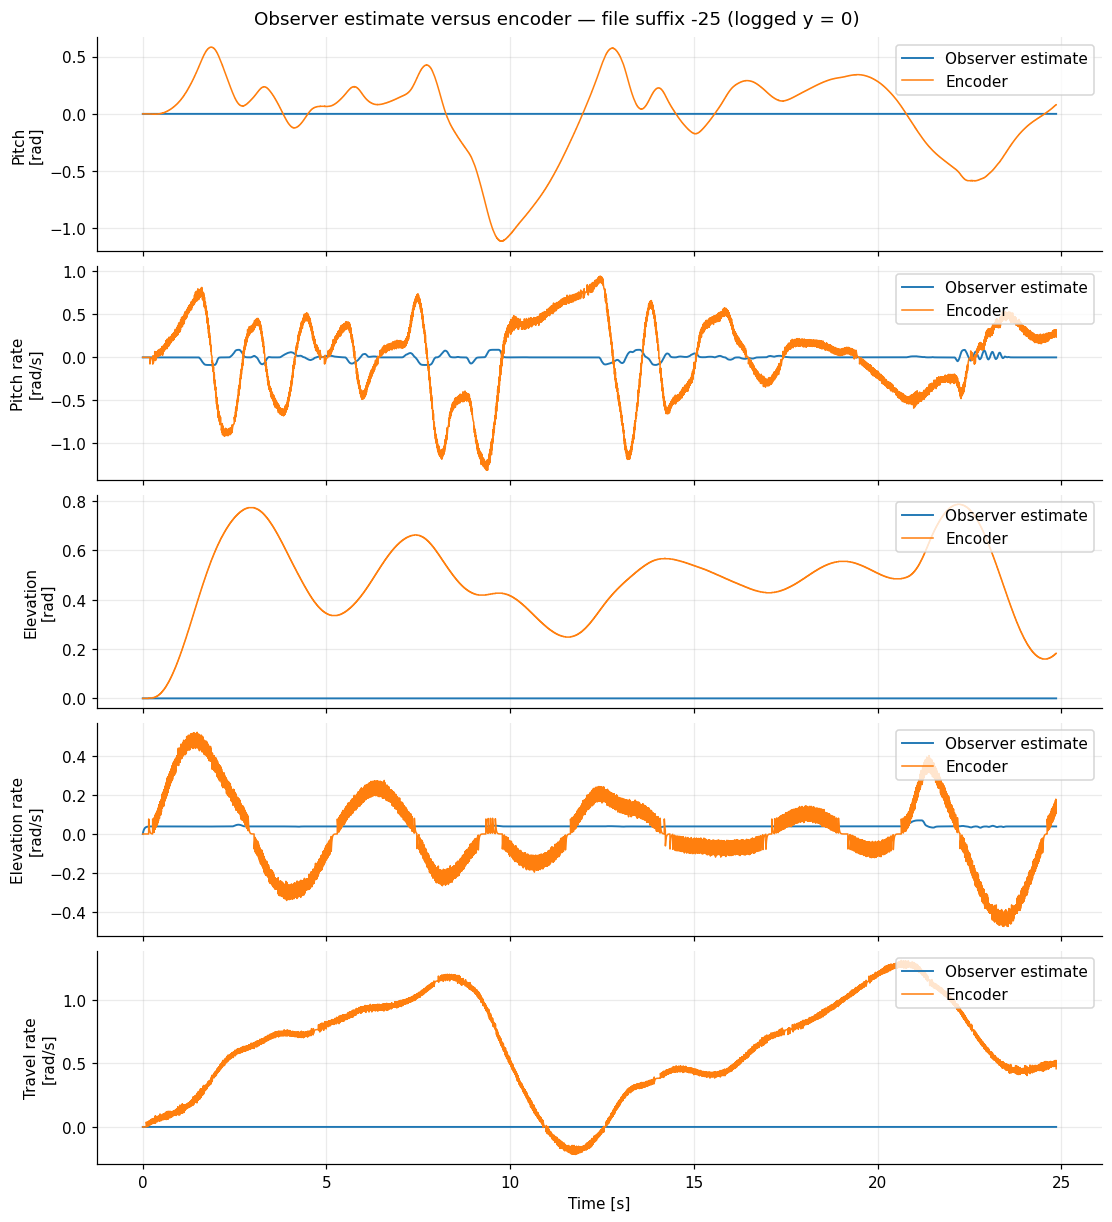

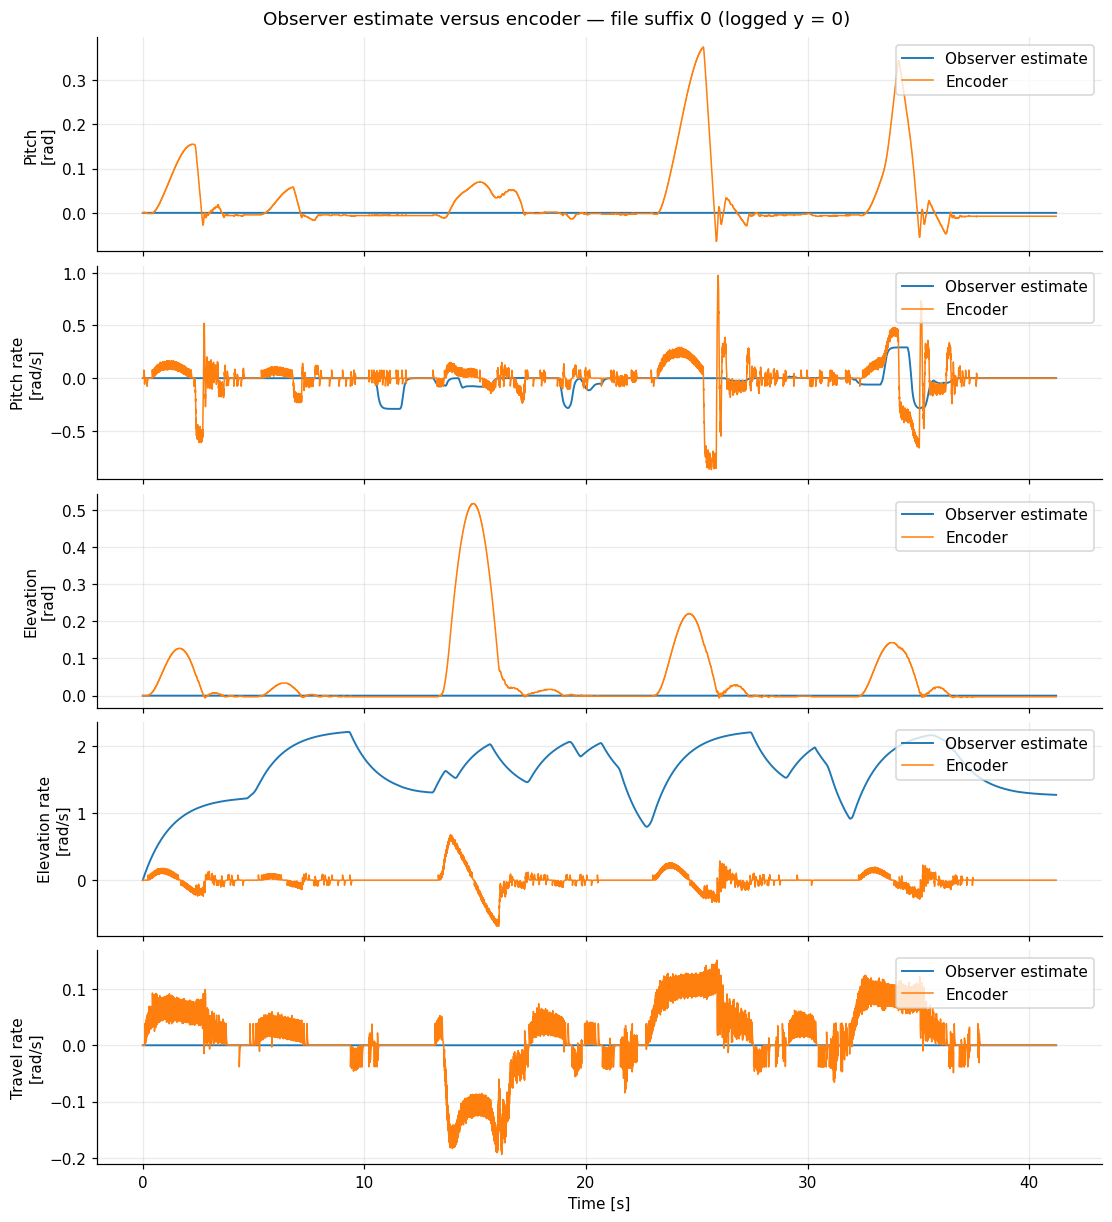

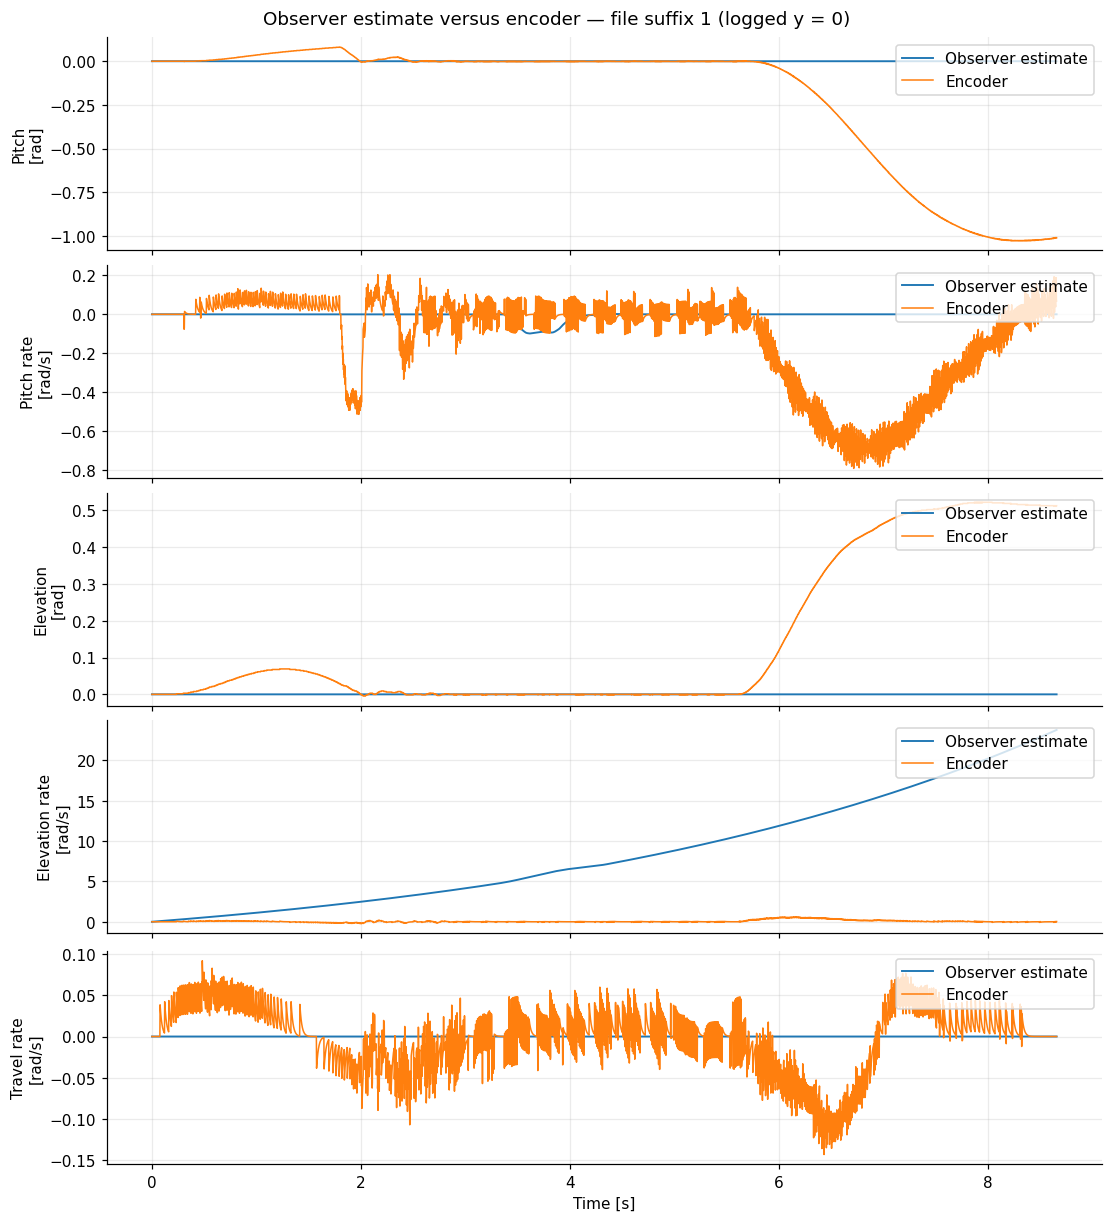

In [10]:
for number, run in enumerate(RUN_IDS, start=1):
    t, enc = load_recording(f"task34_enkoder{run}.mat")
    _, xhat = load_recording(f"task34_xhat{run}.mat")

    fig, axs = plt.subplots(5, 1, figsize=(10, 11), sharex=True, layout="constrained")
    for i, ax in enumerate(axs):
        ax.plot(t, xhat[i], label="Observer estimate", lw=1.25)
        ax.plot(t, enc[ENCODER_STATE_ROWS[i]], label="Encoder", lw=1)
        ax.set_ylabel(f"{STATE_NAMES[i]}\n[{STATE_UNITS[i]}]")
        ax.legend(loc="upper right")
    axs[-1].set_xlabel("Time [s]")
    fig.suptitle(f"Observer estimate versus encoder — file suffix {run} (logged y = 0)")
    # Prefix ensures that the files sort in a logical order in the Plots folder.
    save_plot(fig, f"3.4_{number:02d}_observer_{run.replace('-', 'm')}")

## 5. Interpretation and follow-up

**What can be used in the report:**

1. **Task 1** plots support discussion of gyro/encoder agreement for separate rotations, mismatch for combined rotations, and the accelerometer response to moving the helicopter.
2. **Task 2** plots support a comparison of raw versus transformed gyro rates. The transformed pitch rate agrees particularly well with the encoder. Both pitch-angle wrapping and a notable elevation-angle bias should be discussed.
3. **Observer task:** the plots are *diagnostic only* because the logged measurement inputs are identically zero. The data cannot establish that a Luenberger observer correctly reconstructs the states from IMU measurements. Do not present the plots as evidence that a particular pole vector gives optimal estimation performance.

**Potential checks on the lab computer / in the original model:** inspect the actual `y` signal before the observer (Scope and `To File`), the IMU serial port and new-data indication, and whether a new run was saved after the signal path was corrected. The supplied files cannot establish which one caused the all-zero recordings.

**Controller configuration:** the delivered `.m` file has `gamma_max = zeta_max = 0.2`, but it also appends two zero columns to the LQR gain `K`. Consequently this saved version does not feed back integral states through `K`; confirm the effective MATLAB variables at the time of any laboratory run before claiming integral action was active.

The original files have not been altered; all plots can be regenerated from the notebook.
